In [1]:
import zipfile
import os

with zipfile.ZipFile('/content/semantic_search_experiment.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/')

os.chdir('/content/semantic_search_experiment')

print(os.listdir())

['corpus.csv', 'run_experiment.py', 'qrels.csv', 'queries.csv', 'README.md', 'bm25_baseline_results.csv']


In [2]:
!pip install sentence-transformers pandas numpy

In [3]:
!python run_experiment.py

modules.json: 100% 349/349 [00:00<00:00, 1.11MB/s]
config_sentence_transformers.json: 100% 116/116 [00:00<00:00, 287kB/s]
README.md: 100% 10.5k/10.5k [00:00<00:00, 17.9MB/s]
sentence_bert_config.json: 100% 53.0/53.0 [00:00<00:00, 145kB/s]
config.json: 100% 612/612 [00:00<00:00, 1.67MB/s]

model.safetensors: downloading bytes:  94% 85.0M/90.9M [00:00<00:00, 115MB/s, 7.39MB/s  ]
model.safetensors: downloading bytes: 100% 85.0M/85.0M [00:01<00:00, 79.1MB/s, 8.18MB/s  ]
model.safetensors: reconstructing file: 100% 90.9M/90.9M [00:01<00:00, 84.5MB/s, 8.87MB/s  ]
Loading weights: 100% 103/103 [00:00<00:00, 5085.50it/s]
tokenizer_config.json: 100% 350/350 [00:00<00:00, 1.31MB/s]
vocab.txt: 100% 232k/232k [00:00<00:00, 63.0MB/s]
tokenizer.json: 100% 466k/466k [00:00<00:00, 92.7MB/s]
special_tokens_map.json: 100% 112/112 [00:00<00:00, 487kB/s]
config.json: 100% 190/190 [00:00<00:00, 871kB/s]
\nPER-QUERY RESULTS
query_id                                                      query               BM

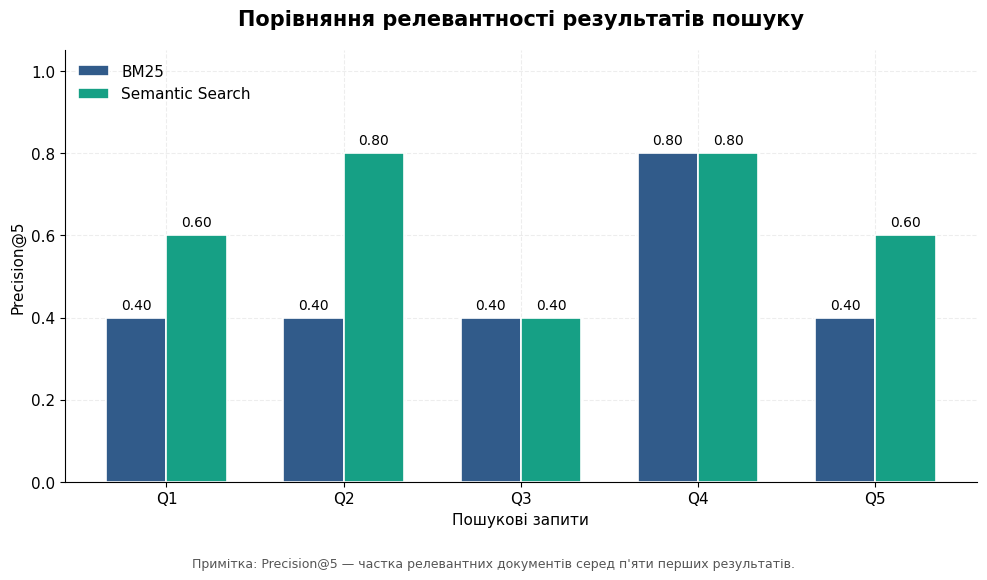

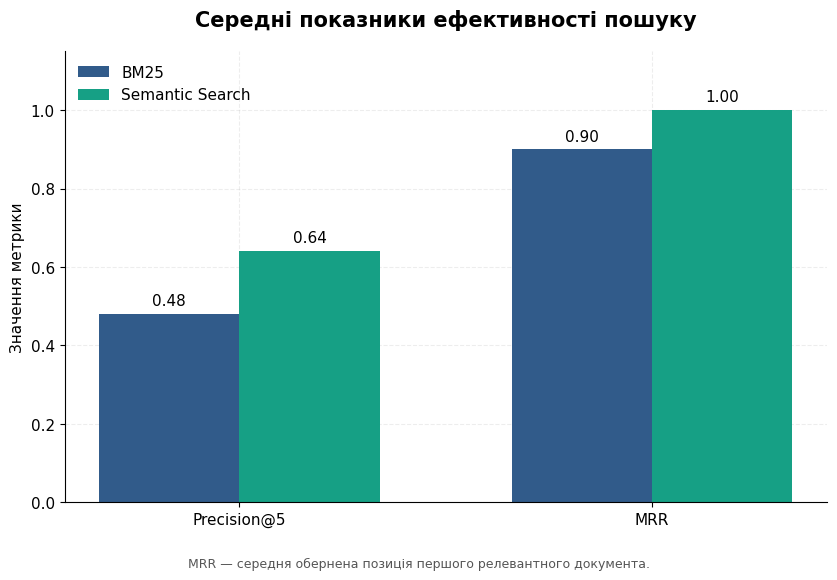

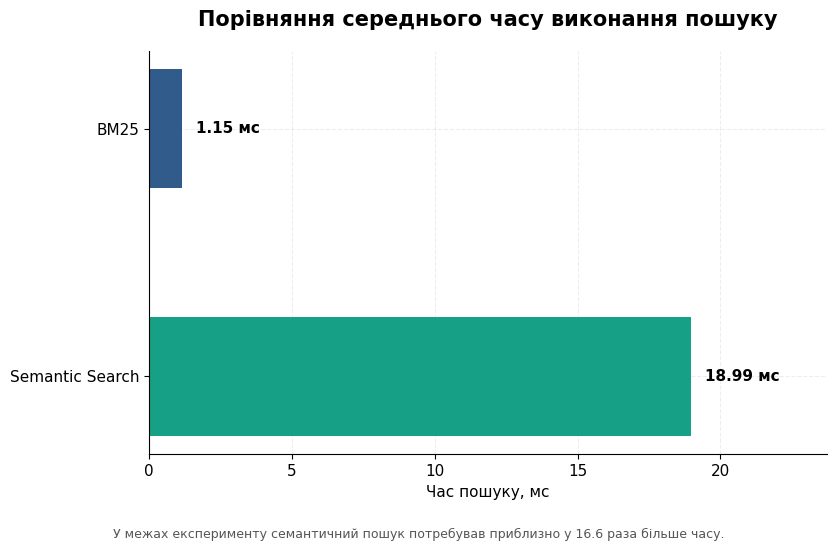


ЕКСПЕРИМЕНТАЛЬНІ ВІЗУАЛІЗАЦІЇ УСПІШНО СТВОРЕНО!
Кількість рисунків: 3
Формати: PNG (300 DPI) та SVG
Папка з рисунками: /content/figures_theses
Архів для завантаження: /content/figures_for_theses.zip

СЕРЕДНІ РЕЗУЛЬТАТИ:
Precision@5 (BM25): 0.48
Precision@5 (Semantic Search): 0.64
MRR (BM25): 0.90
MRR (Semantic Search): 1.00

Час пошуку BM25: 1.15 мс
Час пошуку Semantic Search: 18.99 мс
Співвідношення часу: 16.6 раза

Усі файли збережено в папці figures_theses.


In [5]:

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. ЗАВАНТАЖЕННЯ РЕЗУЛЬТАТІВ ЕКСПЕРИМЕНТУ

possible_paths = [
    Path("comparison_results.csv"),
    Path("/content/semantic_search_experiment/comparison_results.csv"),
    Path("/content/comparison_results.csv")
]

csv_path = next((p for p in possible_paths if p.exists()), None)

if csv_path is None:
    raise FileNotFoundError(
        "Файл comparison_results.csv не знайдено. "
        "Перевірте розташування файлу."
    )

df = pd.read_csv(csv_path)

# Створення папки для готових рисунків
output_dir = Path("/content/figures_theses")
output_dir.mkdir(exist_ok=True)

# 2. НАЛАШТУВАННЯ ВІЗУАЛЬНОГО ОФОРМЛЕННЯ

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 11,
    "figure.titlesize": 17,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "grid.linestyle": "--",
    "savefig.dpi": 300,
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

BM25_COLOR = "#315B8A"
SEM_COLOR = "#16A085"

def save_figure(fig, filename):
    """Збереження рисунка у форматах PNG та SVG."""

    fig.savefig(
        output_dir / f"{filename}.png",
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        output_dir / f"{filename}.svg",
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)


# 3. РИСУНОК 1
# ПОРІВНЯННЯ PRECISION@5 ЗА ЗАПИТАМИ

queries = ["Q1", "Q2", "Q3", "Q4", "Q5"]

bm25 = df["BM25_P@5"].values
semantic = df["Semantic_P@5"].values

x = np.arange(len(queries))
width = 0.34

fig, ax = plt.subplots(figsize=(10, 5.8))

bars1 = ax.bar(
    x - width/2,
    bm25,
    width,
    label="BM25",
    color=BM25_COLOR,
    edgecolor="white",
    linewidth=1.2
)

bars2 = ax.bar(
    x + width/2,
    semantic,
    width,
    label="Semantic Search",
    color=SEM_COLOR,
    edgecolor="white",
    linewidth=1.2
)

ax.set_title(
    "Порівняння релевантності результатів пошуку",
    pad=18,
    fontweight="bold"
)

ax.set_ylabel("Precision@5")
ax.set_xlabel("Пошукові запити")
ax.set_xticks(x)
ax.set_xticklabels(queries)
ax.set_ylim(0, 1.05)

ax.legend(frameon=False, loc="upper left")
ax.yaxis.grid(True)
ax.set_axisbelow(True)

ax.bar_label(bars1, fmt="%.2f", padding=4, fontsize=10)
ax.bar_label(bars2, fmt="%.2f", padding=4, fontsize=10)

fig.text(
    0.5,
    0.01,
    "Примітка: Precision@5 — частка релевантних документів серед п'яти перших результатів.",
    ha="center",
    fontsize=9,
    color="#555555"
)

fig.tight_layout(rect=[0, 0.05, 1, 1])

save_figure(fig, "figure_1_precision_by_query")


# 4. РИСУНОК 2
# ПОРІВНЯННЯ СЕРЕДНІХ ЗНАЧЕНЬ МЕТРИК

metrics = ["Precision@5", "MRR"]

bm25_means = [
    df["BM25_P@5"].mean(),
    df["BM25_MRR"].mean()
]

semantic_means = [
    df["Semantic_P@5"].mean(),
    df["Semantic_MRR"].mean()
]

x = np.arange(len(metrics))

fig, ax = plt.subplots(figsize=(8.5, 5.8))

bars1 = ax.bar(
    x - width/2,
    bm25_means,
    width,
    label="BM25",
    color=BM25_COLOR
)

bars2 = ax.bar(
    x + width/2,
    semantic_means,
    width,
    label="Semantic Search",
    color=SEM_COLOR
)

ax.set_title(
    "Середні показники ефективності пошуку",
    pad=18,
    fontweight="bold"
)

ax.set_ylabel("Значення метрики")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.15)

ax.legend(frameon=False)
ax.set_axisbelow(True)

ax.bar_label(bars1, fmt="%.2f", padding=4, fontsize=11)
ax.bar_label(bars2, fmt="%.2f", padding=4, fontsize=11)

fig.text(
    0.5,
    0.01,
    "MRR — середня обернена позиція першого релевантного документа.",
    ha="center",
    fontsize=9,
    color="#555555"
)

fig.tight_layout(rect=[0, 0.05, 1, 1])

save_figure(fig, "figure_2_mean_metrics")


# 5. РИСУНОК 3
# ПОРІВНЯННЯ ЧАСУ ВИКОНАННЯ ПОШУКУ

time_bm25 = df["BM25_search_ms"].mean()
time_semantic = df["Semantic_search_ms"].mean()

fig, ax = plt.subplots(figsize=(8.5, 5.5))

labels = ["BM25", "Semantic Search"]
times = [time_bm25, time_semantic]
colors = [BM25_COLOR, SEM_COLOR]

bars = ax.barh(
    labels,
    times,
    color=colors,
    height=0.48
)

ax.set_title(
    "Порівняння середнього часу виконання пошуку",
    pad=18,
    fontweight="bold"
)

ax.set_xlabel("Час пошуку, мс")
ax.set_xlim(0, max(times) * 1.25)
ax.invert_yaxis()
ax.set_axisbelow(True)

for bar, value in zip(bars, times):
    ax.text(
        value + max(times) * 0.025,
        bar.get_y() + bar.get_height()/2,
        f"{value:.2f} мс",
        va="center",
        fontweight="bold",
        fontsize=11
    )

ratio = time_semantic / time_bm25

fig.text(
    0.5,
    0.01,
    f"У межах експерименту семантичний пошук потребував приблизно у {ratio:.1f} раза більше часу.",
    ha="center",
    fontsize=9,
    color="#555555"
)

fig.tight_layout(rect=[0, 0.05, 1, 1])

save_figure(fig, "figure_3_search_time")


# 6. ЗБЕРЕЖЕННЯ ВСІХ РИСУНКІВ В АРХІВІ

zip_path = Path("/content/figures_for_theses.zip")

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for file in output_dir.iterdir():
        archive.write(file, arcname=file.name)


# 7. ПІДСУМКОВА ІНФОРМАЦІЯ

print("\nЕКСПЕРИМЕНТАЛЬНІ ВІЗУАЛІЗАЦІЇ УСПІШНО СТВОРЕНО!")

print("Кількість рисунків: 3")
print("Формати: PNG (300 DPI) та SVG")

print(f"Папка з рисунками: {output_dir}")
print(f"Архів для завантаження: {zip_path}")

print("\nСЕРЕДНІ РЕЗУЛЬТАТИ:")

print(f"Precision@5 (BM25): {df['BM25_P@5'].mean():.2f}")
print(f"Precision@5 (Semantic Search): {df['Semantic_P@5'].mean():.2f}")

print(f"MRR (BM25): {df['BM25_MRR'].mean():.2f}")
print(f"MRR (Semantic Search): {df['Semantic_MRR'].mean():.2f}")

print(f"\nЧас пошуку BM25: {time_bm25:.2f} мс")
print(f"Час пошуку Semantic Search: {time_semantic:.2f} мс")
print(f"Співвідношення часу: {ratio:.1f} раза")

print("\nУсі файли збережено в папці figures_theses.")
